📂 Loading data from: data/merged_raw-dataset.xlsx
🏷️ Extracted prefix: merged_raw-dataset
📊 Dataset Shape: (13959, 9)
🌟 Total unique combinations in dataset: 664
✅ Table saved to 'tables\merged_raw-dataset_top10_combinations.csv'
✅ Analysis complete. Image saved to 'plots\merged_raw-dataset_top10_combinations_distribution.png'


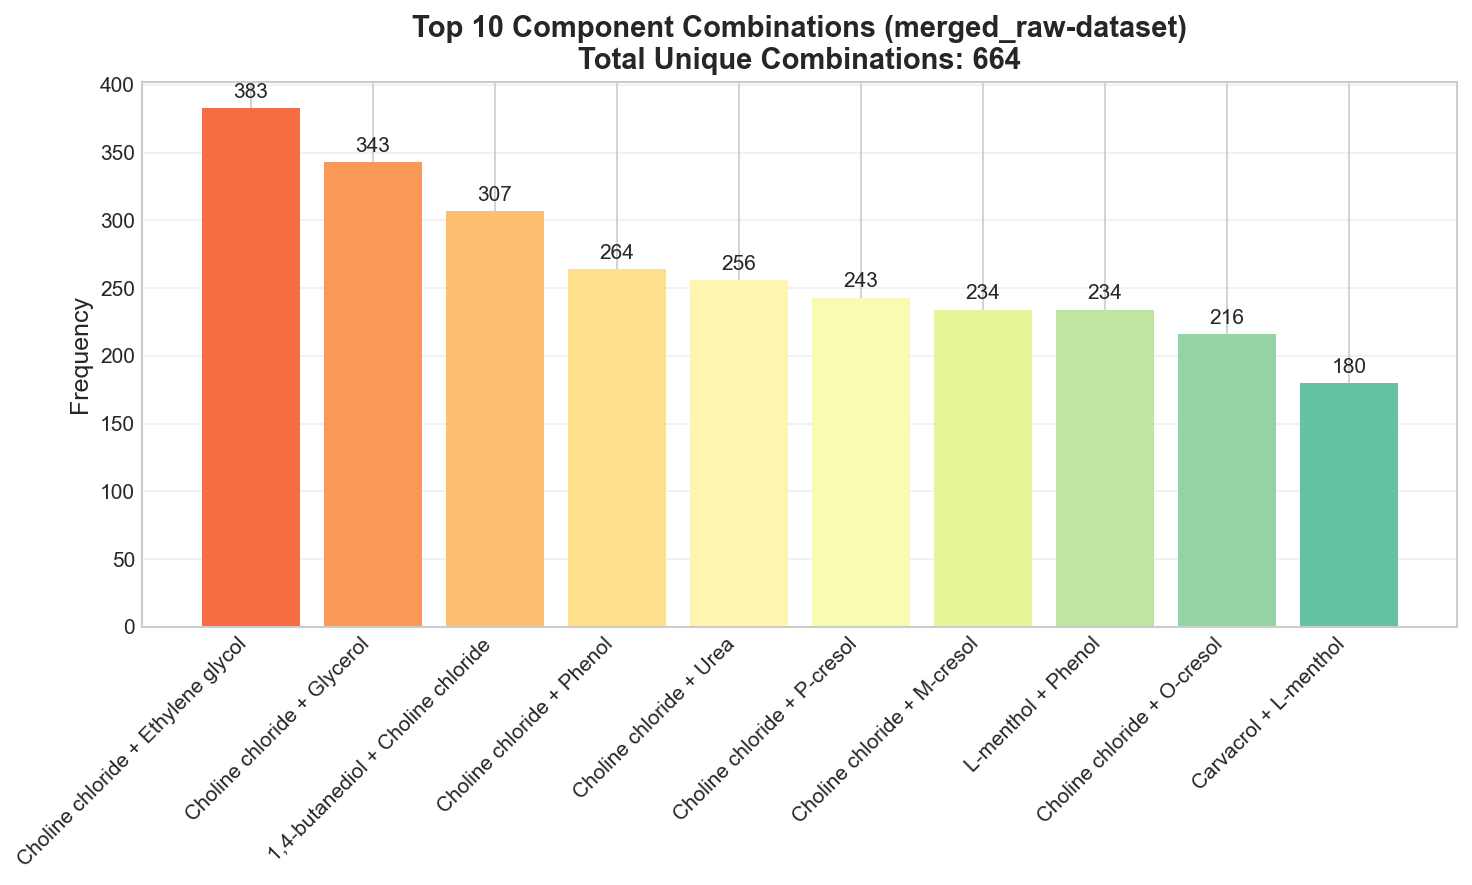

In [12]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

class Config:
    # 数据路径
    DATA_PATH = 'data/merged_raw-dataset.xlsx' 
    PLOTS_DIR = 'plots'
    TABLES_DIR = 'tables'

def analyze_des_compounds(df, columns_to_analyze, tables_output_path, plots_output_path, file_prefix):
    """
    封装好的分析函数：负责创建目录、计算组合频率（置换不变性）、生成表格和绘图
    增加参数 file_prefix 用于给输出文件命名
    """
    # 1. 确保输出目录存在 (Robustness)
    os.makedirs(tables_output_path, exist_ok=True)
    os.makedirs(plots_output_path, exist_ok=True)

    # 2. 设置绘图风格 (兼容性修复)
    try:
        plt.style.use('seaborn-v0_8-whitegrid') # 新版写法
    except OSError:
        try:
            plt.style.use('seaborn-whitegrid')  # 旧版写法
        except:
            plt.style.use('ggplot')             # 万能兜底写法
    
    print(f"📊 Dataset Shape: {df.shape}")

    # 检查指定的列是否存在于 DataFrame 中
    valid_cols = [col for col in columns_to_analyze if col in df.columns]
    missing_cols = set(columns_to_analyze) - set(valid_cols)
    if missing_cols:
        print(f"⚠️ Warning: Missing columns {missing_cols}. They will be skipped.")
    
    if not valid_cols:
        print("❌ Error: No valid columns to analyze.")
        return

    # 3. 计算组合（置换不变性核心逻辑）
    def get_sorted_combination(row):
        # 提取非空值，转为字符串并去除两端空格，统一首字母大写避免同物不同名
        vals = [str(val).strip().capitalize() for val in row if pd.notna(val) and str(val).strip() != '']
        # 排序保证置换不变性: [B, A] 排序后变成 [A, B]
        vals.sort()
        # 用 " + " 连接成组合的唯一标识符
        return " + ".join(vals)

    # 应用函数获取每一行的组合标识
    combinations = df[valid_cols].apply(get_sorted_combination, axis=1)
    
    # 过滤掉完全为空的组合
    combinations = combinations[combinations != '']

    # ✨ 新增逻辑：统计总共的唯一组合种类数
    total_unique_combinations = combinations.nunique()
    print(f"🌟 Total unique combinations in dataset: {total_unique_combinations}")

    # 计算不同组合出现的频率，取前 10
    counts = combinations.value_counts().head(10)
    
    # 4. 保存表格 (加上文件前缀)
    top10_df = pd.DataFrame({'Combination': counts.index, 'Frequency': counts.values})
    csv_name = f"{file_prefix}_top10_combinations.csv"
    top10_df.to_csv(os.path.join(tables_output_path, csv_name), index=False)
    print(f"✅ Table saved to '{os.path.join(tables_output_path, csv_name)}'")
    
    # 5. 绘图逻辑
    fig, ax = plt.subplots(figsize=(10, 6), dpi=150)
    colors = plt.cm.Spectral(np.linspace(0.2, 0.8, len(counts)))
    bars = ax.bar(range(len(counts)), counts.values, color=colors)
    
    # ✨ 标题同步修改：将总组合数也展示在图表标题上
    title_text = f'Top 10 Component Combinations ({file_prefix})\nTotal Unique Combinations: {total_unique_combinations}'
    ax.set_title(title_text, fontsize=14, fontweight='bold')
    ax.set_xticks(range(len(counts)))
    
    # 为了防止组合名称过长导致重叠，对过长的名称截断加上省略号
    max_label_length = 35
    labels = [label if len(label) <= max_label_length else label[:max_label_length-3] + '...' for label in counts.index]
    ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=10)
    ax.set_ylabel('Frequency', fontsize=12)
    ax.grid(True, axis='y', alpha=0.3)

    # 在柱状图上方显示具体数值
    ax.bar_label(bars, padding=3, fontsize=10) 

    # 6. 调整布局
    plt.tight_layout()
    
    # 7. 保存图片 (加上文件前缀)
    plot_save_path = os.path.join(plots_output_path, f'{file_prefix}_top10_combinations_distribution.png')
    plt.savefig(plot_save_path, bbox_inches='tight')
    print(f"✅ Analysis complete. Image saved to '{plot_save_path}'")
    
    # 8. 显示图片
    plt.show() 

# --- Execution Block (执行部分) ---

if __name__ == "__main__":
    # 1. 智能加载数据
    try:
        print(f"📂 Loading data from: {Config.DATA_PATH}")
        
        if Config.DATA_PATH.endswith('.xlsx'):
            df_loaded = pd.read_excel(Config.DATA_PATH)
        elif Config.DATA_PATH.endswith('.csv'):
            df_loaded = pd.read_csv(Config.DATA_PATH)
        else:
            try:
                df_loaded = pd.read_excel(Config.DATA_PATH)
            except:
                df_loaded = pd.read_csv(Config.DATA_PATH)

        # 自动提取文件名作为前缀
        file_prefix = os.path.splitext(os.path.basename(Config.DATA_PATH))[0]
        print(f"🏷️ Extracted prefix: {file_prefix}")

        # 这里传入想要进行组合分析的列的名称
        cols_to_analyze = ['c1', 'c2', 'c3']

        # 2. 调用封装好的分析函数，并传入提取到的 file_prefix
        analyze_des_compounds(df_loaded, cols_to_analyze, Config.TABLES_DIR, Config.PLOTS_DIR, file_prefix)

    except FileNotFoundError:
        print(f"❌ Error: File not found at {Config.DATA_PATH}")
    except Exception as e:
        print(f"❌ An error occurred: {e}")

📂 Loading data from: data/merged_raw-dataset.xlsx
🏷️ Extracted prefix: merged_raw-dataset
🔍 正在处理数据列: 't' ...
📈 原始数据行数: 13959, 清洗后有效数值行数: 13956
🌡️ 覆盖范围 (Coverage Range): 278.15 ~ 378.15 (跨度: 100.00)
📊 统计数据已保存: tables\merged_raw-dataset_t_statistics.csv
✅ 图片已保存: plots\merged_raw-dataset_t_distribution.png


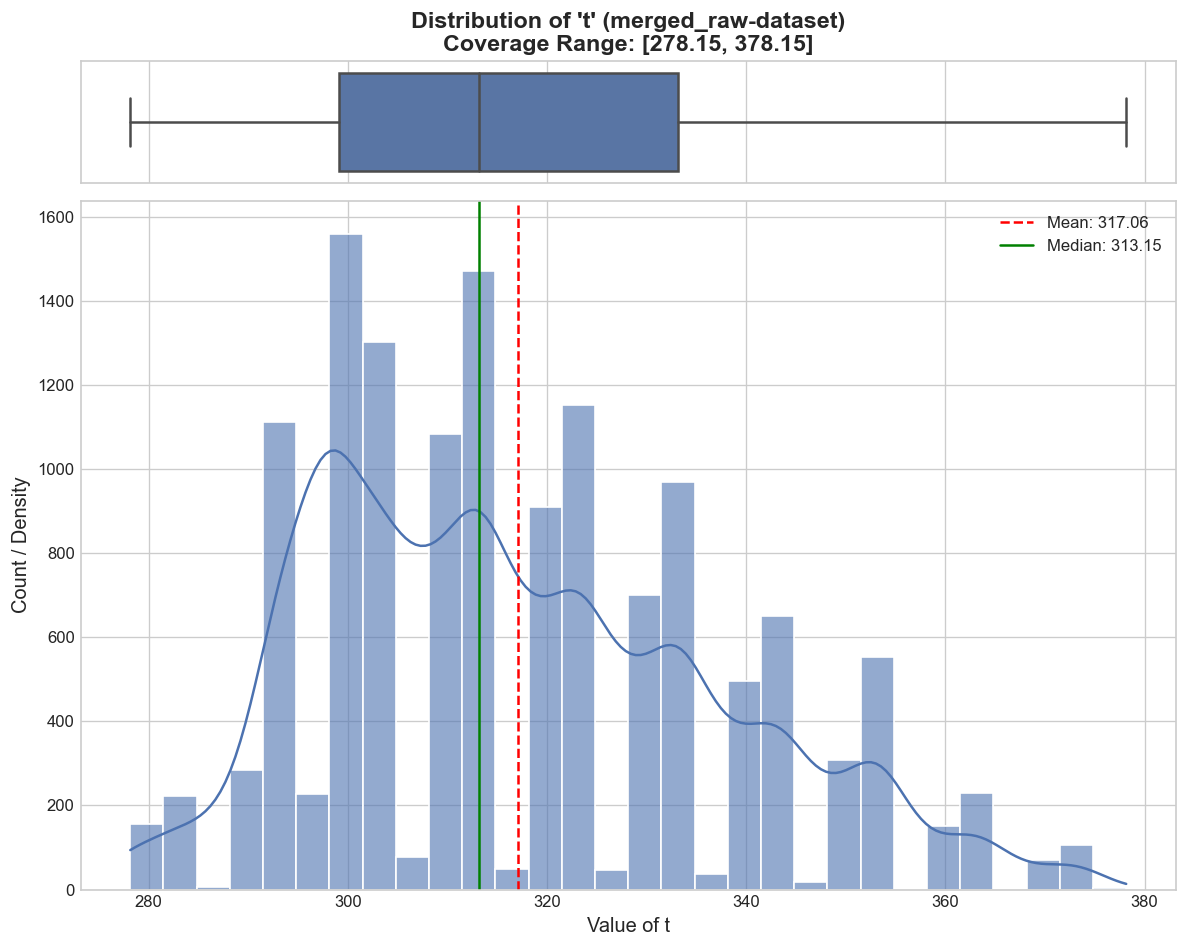

In [20]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

class Config:
    # 数据路径
    DATA_PATH = 'data/merged_raw-dataset.xlsx' 
    PLOTS_DIR = 'plots'
    TABLES_DIR = 'tables'

def analyze_t_distribution(df, target_col, tables_path, plots_path, file_prefix):
    """
    专门针对数值型字段进行分布分析
    生成：统计数据CSV + 箱线图/直方图组合图
    """
    # 1. 基础设置
    os.makedirs(tables_path, exist_ok=True)
    os.makedirs(plots_path, exist_ok=True)
    
    # 设置风格
    try:
        plt.style.use('seaborn-v0_8-whitegrid')
    except OSError:
        try:
            plt.style.use('seaborn-whitegrid')
        except:
            plt.style.use('ggplot')

    # 2. 数据清洗 (关键步骤)
    if target_col not in df.columns:
        print(f"❌ Error: Column '{target_col}' not found in dataset.")
        print(f"💡 Available columns are: {df.columns.tolist()}")
        return

    print(f"🔍 正在处理数据列: '{target_col}' ...")
    # 强制转换为数值型，非数字变为 NaN，然后删除 NaN
    clean_series = pd.to_numeric(df[target_col], errors='coerce').dropna()
    
    print(f"📈 原始数据行数: {len(df)}, 清洗后有效数值行数: {len(clean_series)}")

    if len(clean_series) == 0:
        print(f"❌ Error: No valid numeric data found in column '{target_col}'.")
        return

    # 3. 计算统计指标
    stats = clean_series.describe()
    stats['skewness'] = clean_series.skew() # 偏度
    stats['kurtosis'] = clean_series.kurt() # 峰度
    
    # ✨ 新增：统计温度覆盖范围 (Coverage Range)
    min_val = clean_series.min()
    max_val = clean_series.max()
    coverage_span = max_val - min_val
    stats['coverage_span'] = coverage_span # 将跨度也加入统计表
    
    print(f"🌡️ 覆盖范围 (Coverage Range): {min_val} ~ {max_val} (跨度: {coverage_span:.2f})")
    
    # 保存统计结果到 CSV
    stats_df = pd.DataFrame(stats).reset_index()
    stats_df.columns = ['Metric', 'Value']
    
    # 提取安全的文件名（将列名中的空格、逗号替换为下划线，避免保存报错）
    safe_col_name = target_col.replace(' ', '_').replace(',', '').replace('/', '_')
    
    stats_csv_path = os.path.join(tables_path, f'{file_prefix}_{safe_col_name}_statistics.csv')
    stats_df.to_csv(stats_csv_path, index=False)
    print(f"📊 统计数据已保存: {stats_csv_path}")

    # 4. 绘图 (组合图：箱线图 + 直方图)
    # 创建两个子图，共享 X 轴，高度比例 1:5
    fig, (ax_box, ax_hist) = plt.subplots(2, 1, sharex=True, 
                                          gridspec_kw={"height_ratios": (.15, .85)}, 
                                          figsize=(10, 8), dpi=120)
    
    # 颜色设置
    main_color = '#4c72b0' # 经典的深蓝色
    
    # --- 上图：箱线图 (Boxplot) ---
    sns.boxplot(x=clean_series, ax=ax_box, color=main_color, fliersize=3)
    ax_box.set(xlabel='') # 移除上图的 X 标签
    
    # ✨ 修改：将覆盖范围加入到图表的标题中
    title_text = f"Distribution of '{target_col}' ({file_prefix})\nCoverage Range: [{min_val}, {max_val}]"
    ax_box.set_title(title_text, fontsize=14, fontweight='bold')

    # --- 下图：直方图 + KDE密度曲线 ---
    sns.histplot(x=clean_series, ax=ax_hist, kde=True, 
                 bins=30, color=main_color, alpha=0.6, edgecolor='w')
    
    # 添加辅助线 (均值和中位数)
    mean_val = clean_series.mean()
    median_val = clean_series.median()
    
    ax_hist.axvline(mean_val, color='red', linestyle='--', linewidth=1.5, label=f'Mean: {mean_val:.2f}')
    ax_hist.axvline(median_val, color='green', linestyle='-', linewidth=1.5, label=f'Median: {median_val:.2f}')
    
    ax_hist.set_xlabel(f"Value of {target_col}", fontsize=12)
    ax_hist.set_ylabel("Count / Density", fontsize=12)
    ax_hist.legend() # 显示图例

    # 5. 保存与显示
    plt.tight_layout()
    
    save_path = os.path.join(plots_path, f'{file_prefix}_{safe_col_name}_distribution.png')
    plt.savefig(save_path, bbox_inches='tight')
    print(f"✅ 图片已保存: {save_path}")
    
    plt.show()

# --- Execution Block ---
if __name__ == "__main__":
    try:
        # 1. 智能加载数据
        print(f"📂 Loading data from: {Config.DATA_PATH}")
        if Config.DATA_PATH.endswith('.xlsx'):
            df_loaded = pd.read_excel(Config.DATA_PATH)
        elif Config.DATA_PATH.endswith('.csv'):
            df_loaded = pd.read_csv(Config.DATA_PATH)
        else:
            try:
                df_loaded = pd.read_excel(Config.DATA_PATH)
            except:
                df_loaded = pd.read_csv(Config.DATA_PATH)

        # 自动提取文件名作为前缀
        file_prefix = os.path.splitext(os.path.basename(Config.DATA_PATH))[0]
        print(f"🏷️ Extracted prefix: {file_prefix}")

        # 设置想要分析的目标列名称
        target_column = "t"

        # 2. 执行分析并传入前缀和目标列
        analyze_t_distribution(df_loaded, target_column, Config.TABLES_DIR, Config.PLOTS_DIR, file_prefix)

    except FileNotFoundError:
        print(f"❌ Error: File not found at {Config.DATA_PATH}")
    except Exception as e:
        import traceback
        traceback.print_exc()
        print(f"❌ An error occurred: {e}")

📂 Loading data from: data/merged_raw-dataset.xlsx
🏷️ Extracted prefix: merged_raw-dataset
🔍 正在处理数据列: 'vis' ...
📈 原始数据行数: 13959, 清洗后有效数值行数: 13956
🌡️ 原始数据 覆盖范围: 0.00 ~ 834114.00 (跨度: 834114.00)
🌡️ Log变换 覆盖范围: 0.0000 ~ 13.6341 (跨度: 13.6341)
📊 统计对比表已保存: tables\merged_raw-dataset_vis_log_comparison.csv
✅ 对比图已保存: plots\merged_raw-dataset_vis_log_compare.png


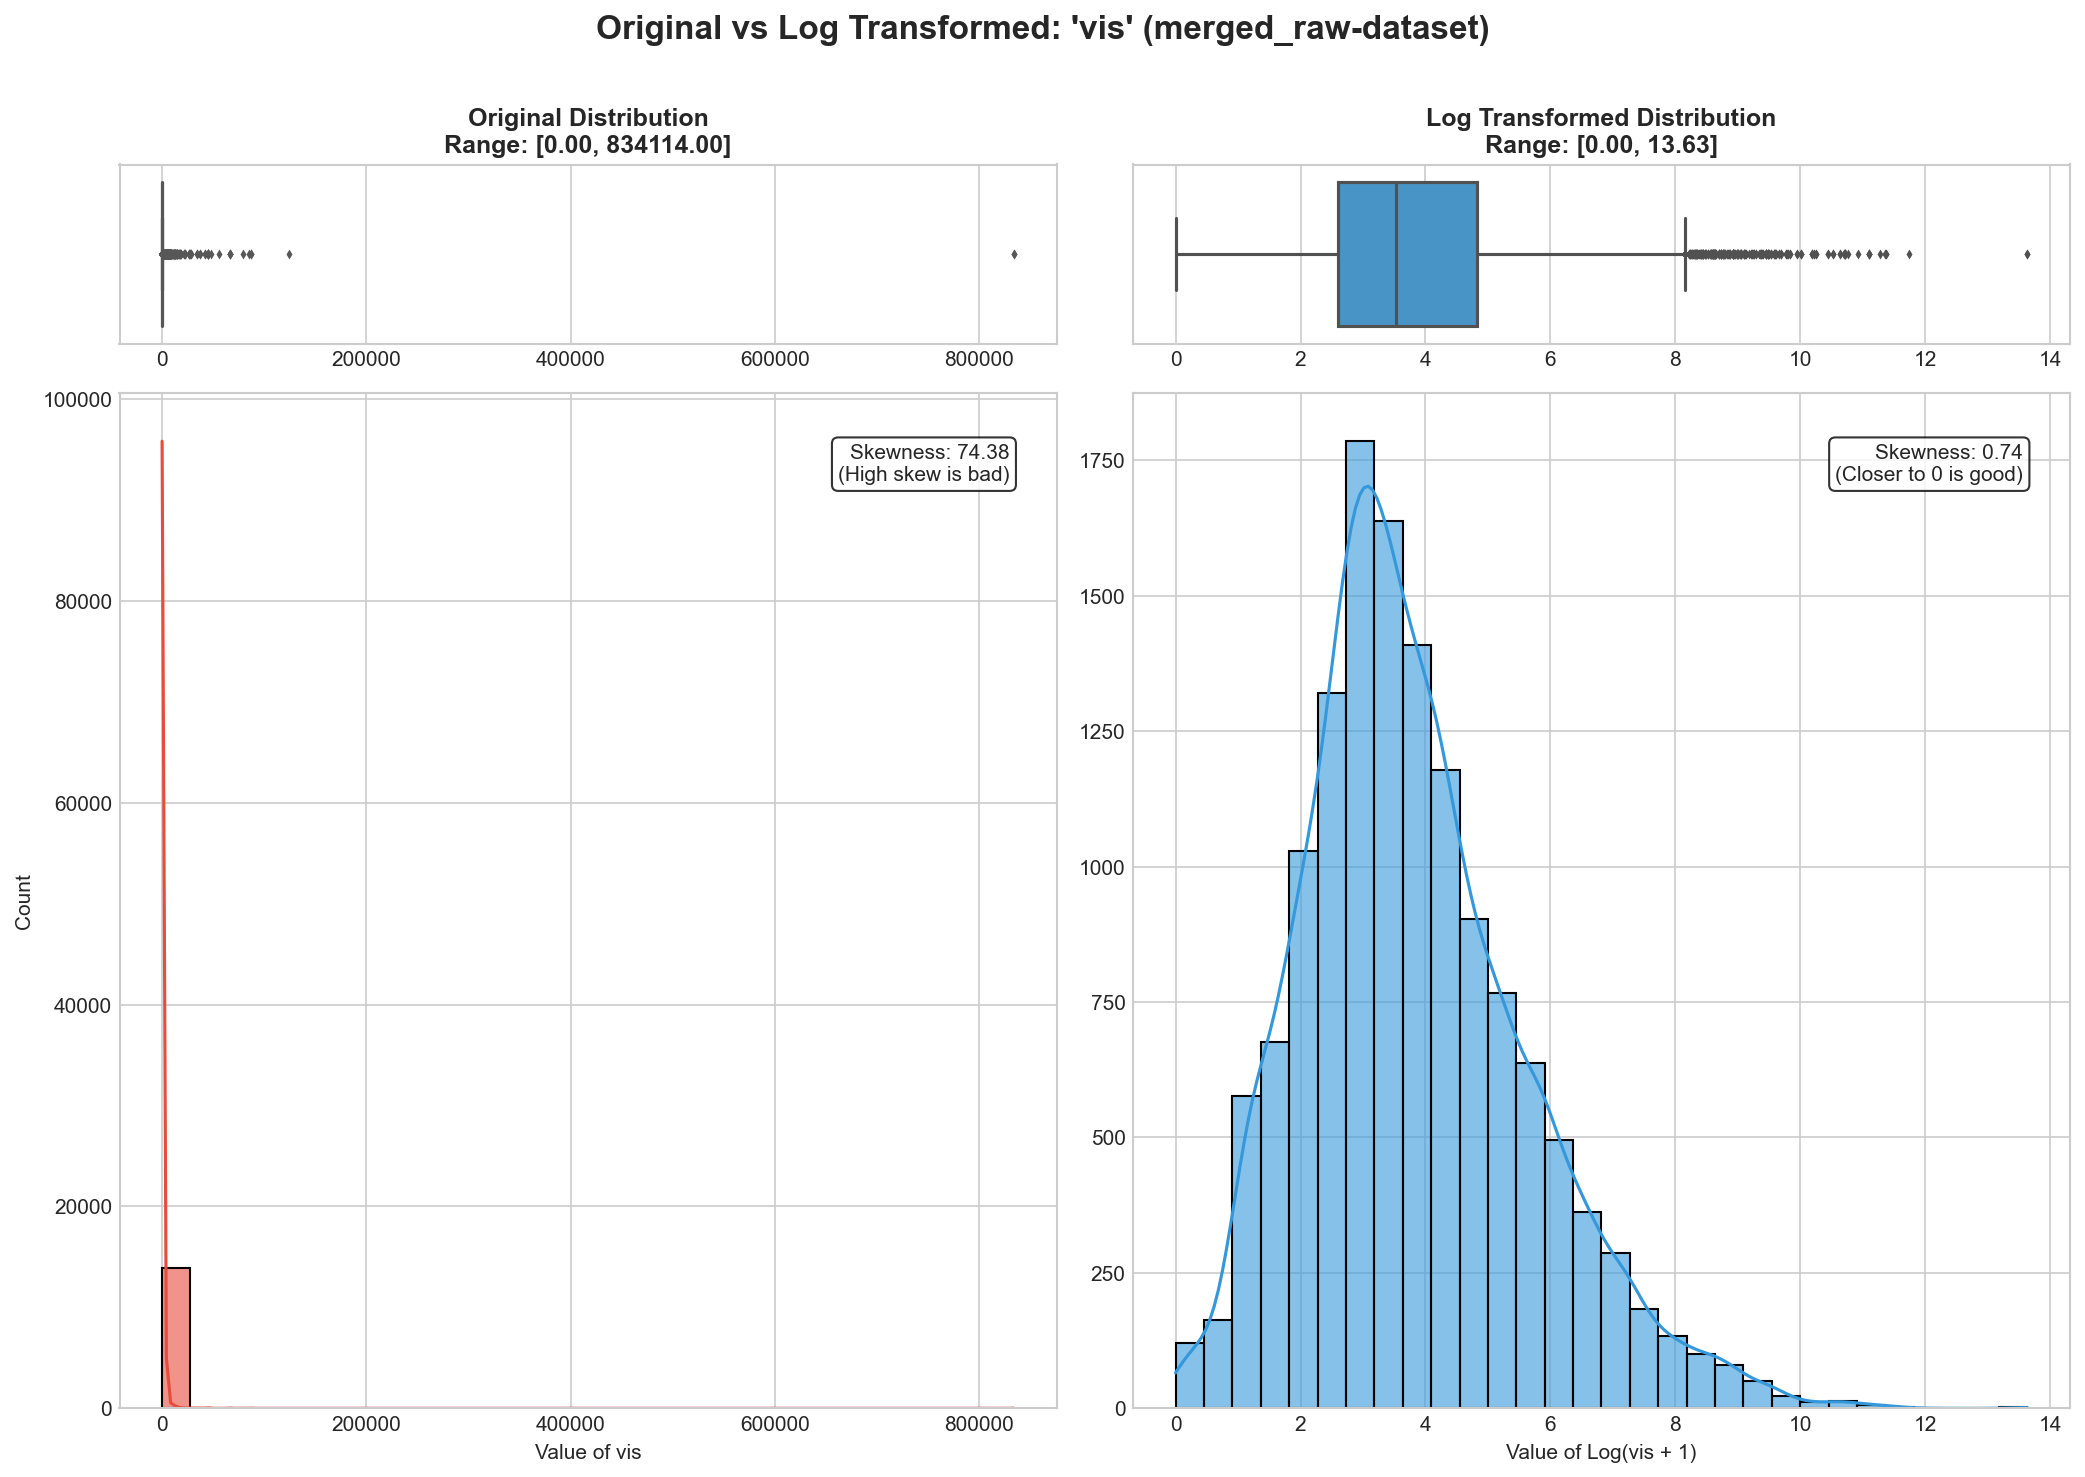

In [28]:
import os
import re  # ✨ 新增：引入正则表达式库处理复杂文件名
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

class Config:
    # 数据路径
    DATA_PATH = 'data/merged_raw-dataset.xlsx' 
    PLOTS_DIR = 'plots'
    TABLES_DIR = 'tables'

def analyze_vis_log_comparison(df, target_col, tables_path, plots_path, file_prefix):
    """
    对比原始数据与 log(x+1) 变换后的数据分布
    增加参数 file_prefix 用于给输出文件命名，target_col 用于指定分析列
    """
    # 1. 基础设置
    os.makedirs(tables_path, exist_ok=True)
    os.makedirs(plots_path, exist_ok=True)
    
    # 设置风格
    try:
        plt.style.use('seaborn-v0_8-whitegrid')
    except OSError:
        try:
            plt.style.use('seaborn-whitegrid')
        except:
            plt.style.use('ggplot')

    # 2. 数据清洗
    if target_col not in df.columns:
        print(f"❌ Error: Column '{target_col}' not found.")
        print(f"💡 Available columns are: {df.columns.tolist()}")
        return

    print(f"🔍 正在处理数据列: '{target_col}' ...")
    
    # 提取数值，去空
    raw_data = pd.to_numeric(df[target_col], errors='coerce').dropna()
    
    # 3. 生成 Log 变换数据 (使用 np.log1p 等价于 log(x+1)，防止 x=0 报错)
    log_data = np.log1p(raw_data)
    
    print(f"📈 原始数据行数: {len(df)}, 清洗后有效数值行数: {len(raw_data)}")

    if len(raw_data) == 0:
        print(f"❌ Error: No valid numeric data found in column '{target_col}'.")
        return

    # 新增：统计覆盖范围 (Coverage Range & Span)
    raw_min, raw_max = raw_data.min(), raw_data.max()
    raw_span = raw_max - raw_min
    
    log_min, log_max = log_data.min(), log_data.max()
    log_span = log_max - log_min
    
    print(f"🌡️ 原始数据 覆盖范围: {raw_min:.2f} ~ {raw_max:.2f} (跨度: {raw_span:.2f})")
    print(f"🌡️ Log变换 覆盖范围: {log_min:.4f} ~ {log_max:.4f} (跨度: {log_span:.4f})")

    # 4. 计算统计对比
    stats_comparison = pd.DataFrame({
        'Metric': ['Mean', 'Median', 'Std', 'Min', 'Max', 'Coverage Span (跨度)', 'Skewness (偏度)', 'Kurtosis (峰度)'],
        'Original': [
            raw_data.mean(), raw_data.median(), raw_data.std(), 
            raw_min, raw_max, raw_span, raw_data.skew(), raw_data.kurt()
        ],
        'Log Transformed (log(x+1))': [
            log_data.mean(), log_data.median(), log_data.std(), 
            log_min, log_max, log_span, log_data.skew(), log_data.kurt()
        ]
    })
    
    # ✨ 核心修复：更强大的文件名安全过滤机制
    # 把除了字母、数字以外的所有符号全部替换成下划线
    safe_col_name = re.sub(r'[^A-Za-z0-9]', '_', target_col)
    # 把连续多个下划线合并为一个，并去掉首尾多余的下划线
    safe_col_name = re.sub(r'_+', '_', safe_col_name).strip('_')
    # 例如：'Viscosity {lg(mPa*s)}' -> 会变成 'Viscosity_lg_mPa_s'
    
    # 保存统计表格
    csv_path = os.path.join(tables_path, f'{file_prefix}_{safe_col_name}_log_comparison.csv')
    stats_comparison.to_csv(csv_path, index=False)
    print(f"📊 统计对比表已保存: {csv_path}")

    # 5. 绘图：2x2 布局 (左列原始，右列Log)
    fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=150, 
                             gridspec_kw={"height_ratios": (.15, .85)})
    
    # 添加整体大标题
    fig.suptitle(f"Original vs Log Transformed: '{target_col}' ({file_prefix})", 
                 fontsize=16, fontweight='bold', y=0.98)
    
    # --- 左列：原始数据 ---
    sns.boxplot(x=raw_data, ax=axes[0, 0], color='#e74c3c', fliersize=2)
    axes[0, 0].set_title(f"Original Distribution\nRange: [{raw_min:.2f}, {raw_max:.2f}]", fontweight='bold')
    axes[0, 0].set_xlabel('')
    
    sns.histplot(x=raw_data, ax=axes[1, 0], kde=True, color='#e74c3c', bins=30, alpha=0.6)
    axes[1, 0].set_xlabel(f"Value of {target_col}")
    axes[1, 0].set_ylabel("Count")
    axes[1, 0].text(0.95, 0.95, f'Skewness: {raw_data.skew():.2f}\n(High skew is bad)', 
                    transform=axes[1, 0].transAxes, ha='right', va='top', 
                    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    # --- 右列：Log变换数据 ---
    sns.boxplot(x=log_data, ax=axes[0, 1], color='#3498db', fliersize=2)
    axes[0, 1].set_title(f"Log Transformed Distribution\nRange: [{log_min:.2f}, {log_max:.2f}]", fontweight='bold')
    axes[0, 1].set_xlabel('')

    sns.histplot(x=log_data, ax=axes[1, 1], kde=True, color='#3498db', bins=30, alpha=0.6)
    axes[1, 1].set_xlabel(f"Value of Log({target_col} + 1)")
    axes[1, 1].set_ylabel("") 
    axes[1, 1].text(0.95, 0.95, f'Skewness: {log_data.skew():.2f}\n(Closer to 0 is good)', 
                    transform=axes[1, 1].transAxes, ha='right', va='top', 
                    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    # 6. 整理布局并保存
    plt.tight_layout()
    plt.subplots_adjust(top=0.88) 
    
    save_path = os.path.join(plots_path, f'{file_prefix}_{safe_col_name}_log_compare.png')
    plt.savefig(save_path, bbox_inches='tight')
    print(f"✅ 对比图已保存: {save_path}")
    
    plt.show()

# --- Execution Block ---
if __name__ == "__main__":
    try:
        print(f"📂 Loading data from: {Config.DATA_PATH}")
        if Config.DATA_PATH.endswith('.xlsx'):
            df_loaded = pd.read_excel(Config.DATA_PATH)
        elif Config.DATA_PATH.endswith('.csv'):
            df_loaded = pd.read_csv(Config.DATA_PATH)
        else:
            try:
                df_loaded = pd.read_excel(Config.DATA_PATH)
            except:
                df_loaded = pd.read_csv(Config.DATA_PATH)

        file_prefix = os.path.splitext(os.path.basename(Config.DATA_PATH))[0]
        print(f"🏷️ Extracted prefix: {file_prefix}")

        target_column = 'vis' 

        analyze_vis_log_comparison(df_loaded, target_column, Config.TABLES_DIR, Config.PLOTS_DIR, file_prefix)

    except FileNotFoundError:
        print(f"❌ Error: File not found at {Config.DATA_PATH}")
    except Exception as e:
        import traceback
        traceback.print_exc()
        print(f"❌ An error occurred: {e}")